# Import

In [10]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE

# Data Preparation

In [ ]:
df = pd.read_csv("cmi_internet.csv")
# legenda = pd.read_csv("data_dictionary.csv")

# Stagioni enceoded winter=0, spring=1, summer=2, autumn=3
df_da_imp = df.copy()

df_da_imp['sds_imputed_mask'] = df_da_imp['SDS-SDS_Total_Raw'].isna()

In [12]:
# Colonne just to check
col_categoriche = df_da_imp.select_dtypes(include=["object"]).columns
col_numeriche = df_da_imp.select_dtypes(
    include=["int64", "float64"]).columns
col_quantitative = df_da_imp.select_dtypes(
    include=["int64", "float64"]).columns.drop("id")

col_da_escludere = [
    "FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
    "FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
    "FGC-FGC_TL_Zone"
]

col_non_bin = col_quantitative.difference(col_da_escludere)

In [13]:
# Select only numerical columns for correlation matrix
numerical_columns = df.select_dtypes(include=['float64', 'int64'])

# Compute the correlation matrix
corr = numerical_columns.corr()

# Heatmap of correlation matrix
'''plt.figure(figsize=(32, 32))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features in Train Data')
plt.tight_layout()
plt.show()'''

'plt.figure(figsize=(32, 32))\nsns.heatmap(corr, annot=True, fmt=".2f", cmap=\'coolwarm\', linewidths=0.5)\nplt.title(\'Correlation Heatmap of Numerical Features in Train Data\')\nplt.tight_layout()\nplt.show()'

In [14]:
# Rimuovere 18+
# 0 = nan da lista
# paq Da arrotondare

# CGAS-CGAS_Score fuori scala

df_da_imp["CGAS-CGAS_Score"] = df_da_imp["CGAS-CGAS_Score"].mask(
    lambda x: x > 100, np.nan)

df_da_imp = df_da_imp[df_da_imp["Basic_Demos-Age"] <= 18]

colonne_zeri = ['Physical-Weight',
                'Physical-Diastolic_BP', 'Physical-Systolic_BP']
df_da_imp[colonne_zeri] = df_da_imp[colonne_zeri].mask(
    lambda x: x == 0, np.nan)

'''
- le stagioni sono da lasciare. una volta imputate si arrotondano i valori che escono per il BMI. 
- i valori delle due colonne bmi sono diversi quindi lo ricalcoliamo noi dopo aver imputato altezza e peso
- da togliere Fitness_Endurance-Time_Mins e Fitness_Endurance-Time_Sec visto 
    che abbiamo crea to Fitness_Endurance-Tempo_totale che le include entrambe
- tutte le paq sono da rimuovere: troppi valori mancanti inoltre non ha senso visto che alcune righe sono considerate sia come 
    adolescenti che come bambini. anche ridondante visto che abbiamo già abbastanza valori sull'attività fisica.
    sono pure fuori scala'''

df_da_imp['Fitness_Endurance-Tempo_totale'] = df_da_imp['Fitness_Endurance-Time_Sec'] + \
    (df_da_imp['Fitness_Endurance-Time_Mins']*60)

df_da_imp = df_da_imp.drop(
    ['Fitness_Endurance-Time_Mins', 'Fitness_Endurance-Time_Sec'], axis=1)

df_da_imp = df_da_imp.drop(
    ['PAQ_A-Season', 'PAQ_A-PAQ_A_Total', 'PAQ_C-Season', 'PAQ_C-PAQ_C_Total'], axis=1)

df_da_imp = df_da_imp.drop(
    ['Physical-BMI', 'BIA-BIA_BMI', 'SDS-SDS_Total_T'], axis=1)

In [15]:
variabili_cat = ['Basic_Demos-Enroll_Season', 'Basic_Demos-Sex', 'CGAS-Season',
                 'Physical-Season', 'Fitness_Endurance-Season', 'FGC-Season',
                 "FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
                 "FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
                 "FGC-FGC_TL_Zone", 'BIA-Season', 'BIA-BIA_Activity_Level_num', 'BIA-BIA_Frame_num',
                 'PCIAT-Season', 'PCIAT-PCIAT_01', 'PCIAT-PCIAT_02', 'PCIAT-PCIAT_03',
                 'PCIAT-PCIAT_04', 'PCIAT-PCIAT_05', 'PCIAT-PCIAT_06', 'PCIAT-PCIAT_07',
                 'PCIAT-PCIAT_08', 'PCIAT-PCIAT_09', 'PCIAT-PCIAT_10', 'PCIAT-PCIAT_11',
                 'PCIAT-PCIAT_12', 'PCIAT-PCIAT_13', 'PCIAT-PCIAT_14', 'PCIAT-PCIAT_15',
                 'PCIAT-PCIAT_16', 'PCIAT-PCIAT_17', 'PCIAT-PCIAT_18', 'PCIAT-PCIAT_19',
                 'PCIAT-PCIAT_20', 'SDS-Season', 'PreInt_EduHx-Season',
                 'PreInt_EduHx-computerinternet_hoursday']

In [16]:
stagioni = {"Winter": 0, "Spring": 1, "Summer": 2, "Fall": 3}
df_lavoro = df_da_imp.replace(stagioni)

X_features = df_lavoro.drop(['id', 'sii', 'sds_imputed_mask'], axis=1)
df_sds_mask = df_lavoro['sds_imputed_mask']
y_target = df_lavoro['sii'].astype(int)
df_id = df_lavoro['id']

X_train, X_test, y_train, y_test, mask_train, mask_test = train_test_split(
    X_features, y_target, df_sds_mask, test_size=0.3, random_state=0, stratify=y_target
)

rf_estimator = RandomForestRegressor(
    n_estimators=20, random_state=222, n_jobs=-1)
imputer_rf = IterativeImputer(
    estimator=rf_estimator, random_state=222, max_iter=5)

X_train_imp_array = imputer_rf.fit_transform(X_train)
X_test_imp_array = imputer_rf.transform(X_test)

X_train_imp = pd.DataFrame(
    X_train_imp_array, columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(
    X_test_imp_array, columns=X_test.columns, index=X_test.index)

train_completo = X_train_imp.assign(sii=y_train, sds_imputed_mask=mask_train)
test_completo = X_test_imp.assign(sii=y_test, sds_imputed_mask=mask_test)

df_final_features = pd.concat([train_completo, test_completo]).sort_index()

df_final_features.insert(0, 'id', df_id)
df_imp_et = df_final_features

C:\Users\Riccardo\AppData\Local\Temp\ipykernel_4836\2801103679.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_lavoro = df_da_imp.replace(stagioni)
c:\Users\Riccardo\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:825: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [17]:
df_imp_et[variabili_cat] = df_imp_et[variabili_cat].round()
df_imp_et["bmi"] = (df_imp_et["Physical-Weight"] /
                    (df_imp_et["Physical-Height"] ** 2)) * 703

In [18]:
# Salvataggio dati in parquet
df_imp_et.to_parquet('df_imp_et.parquet')

# Outliers Detection

In [19]:
df_imp_et = pd.read_parquet('df_imp_et.parquet')
standard_scaler = StandardScaler().set_output(transform="pandas")
minmax_scaler = MinMaxScaler()

droppare_per_X = ['sii', 'id']

y = np.array(df_imp_et['sii'])
X = df_imp_et.drop(droppare_per_X, axis=1)
X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(
    X_standard, y, test_size=0.3, random_state=0)

In [ ]:
X_standard.to_parquet('X_standard.parquet')

In [20]:
# Ensemble: FeaBag

feabag_model = FeatureBagging(
    base_estimator=LOF(),  # stimatore base, si può cambiare
    n_estimators=100,  # da testare coi dati veri per capire quanto ci vuole
    max_features=0.5,  # proporzione di variabili da estrarre per ogni modello
    contamination=0.01,  # come prima, 1% di outliers
    random_state=222,
    n_jobs=-1
)
feabag_model.fit(X_standard)

feabag_preds = feabag_model.predict(X_standard)

c:\Users\Riccardo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Impossibile trovare il file specificato
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Riccardo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Riccardo\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Riccardo\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^

In [21]:
# Foreste: Extended Forest

# In isotree, ndim=1 equivale a Isolation Forest standard.
# Scegliere ndim=df.shape[1] per la Extended Isolation Forest completa.
extended_forest_model = EIF(
    sample_size=256,  # come prima
    ntrees=100,  # numero alberi
    # serve a dire al modello che vogliamo la versione estesa
    ndim=X_standard.shape[1],
    random_seed=222,
    n_jobs=-1
)
extended_forest_model.fit(X_standard)

# EIF genera uno score (più alto = più probabile outlier)
extended_forest_scores = extended_forest_model.predict(X_standard)

# gli outlier vanno trovati a mano
threshold = np.percentile(extended_forest_scores, 99)  # 99 percentile
extended_forest_preds = (extended_forest_scores > threshold).astype(int)

c:\Users\Riccardo\anaconda3\Lib\site-packages\isotree\__init__.py:1737: UserWarning: Instantiating CategoricalDtype without any arguments.Pass a CategoricalDtype instance to silence this warning.
  X_cat = X.select_dtypes(include = [pd.CategoricalDtype, "object", "bool"])
c:\Users\Riccardo\anaconda3\Lib\site-packages\isotree\__init__.py:1757: UserWarning: Instantiating CategoricalDtype without any arguments.Pass a CategoricalDtype instance to silence this warning.
  self.cols_categ_    = X.select_dtypes(include = [pd.CategoricalDtype, "object", "bool"]).columns.to_numpy(copy=True)


91


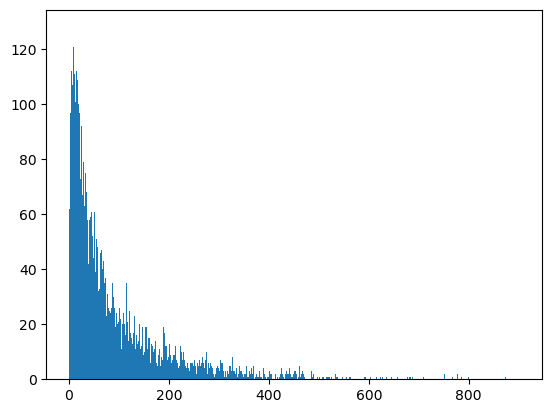

Numero di outlier trovati: 154 (1.85%)


In [22]:
import math as m
# Distanza: RKNN
# 1. Trova i k-vicini per ogni punto
k = int(m.sqrt(len(X_standard)))
nbrs = NearestNeighbors(n_neighbors=k).fit(X_standard)
distances, indices = nbrs.kneighbors(X_standard)
print(k)
# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_standard))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out = np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
# plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')
plt.show()

n_outliers_rknn = np.sum(outliers_rknn)
print(
    f"Numero di outlier trovati: {int(n_outliers_rknn)} ({n_outliers_rknn/len(df_imp_et)*100:.2f}%)")

In [23]:
# Deviation-based Approaches: EllEnv

from sklearn.covariance import EllipticEnvelope

ellenv = EllipticEnvelope(random_state=222, contamination=0.01)
ellenv.fit(X_standard)

# predict returns 1 for an inlier and -1 for an outlier
outliers_ellenv = ellenv.predict(X_standard)

# print (outliers_ellenv)
np.unique(outliers_ellenv, return_counts=True)

n_outliers_ellenv = np.sum(outliers_ellenv == -1)
print(
    f"Numero di outlier trovati: {int(n_outliers_ellenv)} ({n_outliers_ellenv/len(df_imp_et)*100:.2f}%)")

c:\Users\Riccardo\anaconda3\Lib\site-packages\sklearn\covariance\_robust_covariance.py:187: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-171.172789441745380 > -236.693763205782460). You may want to try with a higher value of support_fraction (current value: 0.505).
  warnings.warn(
c:\Users\Riccardo\anaconda3\Lib\site-packages\sklearn\covariance\_robust_covariance.py:187: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-170.977988621069073 > -245.237900982048842). You may want to try with a higher value of support_fraction (current value: 0.505).
  warnings.warn(
c:\Users\Riccardo\anaconda3\Lib\site-packages\sklearn\covariance\_robust_covariance.py:187: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-171.018064592499456 > -198.402371449117879). You may want to try with a higher value of support_fraction (current value: 0.505).
  warning

Numero di outlier trovati: 84 (1.01%)


c:\Users\Riccardo\anaconda3\Lib\site-packages\sklearn\covariance\_robust_covariance.py:187: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-170.891962071701840 > -234.625981494796378). You may want to try with a higher value of support_fraction (current value: 0.505).
  warnings.warn(


In [24]:

# High Dimensionality: Fast ABOD

#!!! LENTO, su portatile in carica ci mette 5+ minuti; sul fisso un paio

# Contamination è la proporzione di outliers; n_neighbors autoesplicativo
abod_model = ABOD(contamination=0.01, n_neighbors=76, n_jobs=-1)
abod_model.fit(X_standard)

# 0 = inliers e 1 = outliers
abod_preds = abod_model.predict(X_standard)
abod_scores = abod_model.decision_scores_

In [25]:
df_outliers = pd.DataFrame(
    np.column_stack((outliers_rknn, outliers_ellenv,
                    feabag_preds, extended_forest_preds, abod_preds)),
    columns=['rknn', 'ellenv', 'feabag', 'ext_forest', 'abod']
)

df_outliers['risultati'] = (
    (df_outliers['rknn'] == 1).astype(int) +
    (df_outliers['ellenv'] == -1).astype(int) +
    (df_outliers['feabag'] == 1).astype(int) +
    (df_outliers['ext_forest'] == 1).astype(int) +
    (df_outliers['abod'] == 1).astype(int)
)

df_outliers_2 = df_outliers[df_outliers['risultati'] >= 2]
df_outliers_1 = df_outliers[df_outliers['risultati'] >= 1]
df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)

In [26]:
# rimossi gli outliers che erano outliers per più di due metodi
df_risultati = df_imp_et.copy()
df_risultati['risultati'] = df_outliers['risultati'].values
df_pulito = df_risultati[df_risultati['risultati'] <= 1].copy()

print(f"Righe originali: {len(df_risultati)}")
print(f"Righe dopo il filtro: {len(df_pulito)}")

df_solo_out = df_risultati[df_risultati['risultati'] > 1].copy()

Righe originali: 8319
Righe dopo il filtro: 8235


In [27]:
df_outliers.to_parquet('df_outliers.parquet')
df_pulito.to_parquet('df_pulito.parquet')

In [28]:
# --- PREPARAZIONE DATASET PER REGRESSIONE ---
# Ora filtriamo df_pulito rimuovendo tutte le righe dove SDS_Total_Raw era stato imputato
df_regression = df_pulito[~df_pulito['sds_imputed_mask']].copy()

# Possiamo droppare la maschera visto che non serve più
df_regression = df_regression.drop(columns=['sds_imputed_mask'])

print(f"Righe in df_pulito (Classificazione): {len(df_pulito)}")
print(
    f"Righe in df_regression (Regressione su valori veri): {len(df_regression)}")

# Salviamo il dataset per i notebook successivi di regressione
df_regression.to_parquet('df_regression.parquet')

Righe in df_pulito (Classificazione): 8235
Righe in df_regression (Regressione su valori veri): 4794


# Dimensionality Reduction


In [ ]:
X_standard = pd.read_parquet('X_standard.parquet')
df_outliers = pd.read_parquet('df_outliers.parquet')

In [ ]:
%%time
#PCA
pca = PCA(n_components=5, random_state=222)
df_unito_pca = pca.fit_transform(X_standard)
print(pca.explained_variance_ratio_.sum()) 

In [ ]:
# 2D
import plotly.express as px
fig, ax = plt.subplots()
plt.scatter(df_unito_pca[:, 0], df_unito_pca[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()


# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_pca[:, 0],
    'Component 2': df_unito_pca[:, 1],
    'Component 3': df_unito_pca[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    color_continuous_scale='Viridis',
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3))  # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()

In [ ]:
%%time
import umap
#UMAP
umappe = umap.UMAP(n_components = 3, n_jobs=-1)
df_unito_umap = umappe.fit_transform(X_standard)

print(umappe)

In [ ]:
# 2D

import pandas as pd
import plotly.express as px
plt.scatter(df_unito_umap[:, 0], df_unito_umap[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_umap[:, 0],
    'Component 2': df_unito_umap[:, 1],
    'Component 3': df_unito_umap[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    color_continuous_scale='Plasma',
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3))  # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()

# Unbalanced Learning

In [ ]:
import warnings
warnings.simplefilter("ignore")

In [ ]:
df_pulito = pd.read_parquet('df_pulito.parquet')
df_unlearn = df_pulito.drop(['risultati'], axis=1).copy()

standard_scaler = StandardScaler().set_output(transform="pandas")

y_da_binarizzare = np.array(df_unlearn['sii'])
y_pulito = np.where(y_da_binarizzare == 3.0, 1, 0)

X_pulito = df_unlearn.drop(columns=['id', 'sii', 'PCIAT-PCIAT_Total']).copy()

X_pulito_s = pd.DataFrame(
    standard_scaler.fit_transform(X_pulito),
    columns=X_pulito.columns,
    index=X_pulito.index
)

X_trainp, X_testp, y_trainp, y_testp = train_test_split(
    X_pulito, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)
X_trainp_s, X_testp_s, y_trainp_s, y_testp_s = train_test_split(
    X_pulito_s, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

# pd.Series(y_pulito).value_counts()
pd.Series(y_testp).value_counts()

In [ ]:
# PCA

pca = PCA(n_components=3, random_state=222)

pca.fit(X_trainp)
X_pca = pca.transform(X_trainp)
print(X_trainp.shape, X_pca.shape)
print(pca.explained_variance_ratio_.sum())

In [ ]:
# CONTROLLARE PER IPERPARAMETRI DI DECISIONTREE
clf = DecisionTreeClassifier(min_samples_leaf=3, random_state=222)
clf.fit(X_trainp, y_trainp)

y_pred0 = clf.predict(X_testp)

print('Accuracy %s' % accuracy_score(y_testp, y_pred0))
print('F1-score %s' % f1_score(y_testp, y_pred0, average=None))
print(classification_report(y_testp, y_pred0))

importances = pd.Series(clf.feature_importances_, index=X_trainp.columns)
print(importances.sort_values(ascending=False).head(5))

# PCIAT-PCIAT_Total            0.942548
# praticamente viene usata solo questa per fare gli split quindi va levata? suppongo

'''Ho rimosso la variabile #PCIAT-PCIAT_Total perché introduceva Target Leakage. Essendo il target una discretizzazione 
del punteggio totale, lasciarla avrebbe reso il problema banale, portando il modello a imparare una semplice regola aritmetica 
anziché i pattern comportamentali sottostanti. Rimuovendola, ho forzato il modello a lavorare sui singoli item, aumentando il valore 
diagnostico e la capacità di generalizzazione su nuovi soggetti di cui potremmo avere solo risposte parziali.

Senza il totale, il Decision Tree inizierà a pesare i singoli comportamenti. 
Scoprirai, ad esempio, che la domanda 20 ("Quanto spesso preferisci stare su internet invece di uscire con gli amici?")
pesa molto più della domanda 4.
Interpretabilità: Potrai dire: "Il modello ha individuato che non è il punteggio totale a contare, ma questi 4 comportamenti specifici 
che, se presenti contemporaneamente, portano alla classe 3".'''

In [ ]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

y_score0 = clf.predict_proba(X_testp)[:, 1]
fpr0, tpr0, thresholds0 = roc_curve(y_testp, y_score0)
roc_auc0 = auc(fpr0, tpr0)

plt.figure(figsize=(6, 4))
plt.plot(fpr0, tpr0, color='limegreen', lw=2,
         label=f'ROC curve class 1 (area = {roc_auc0:.2f})')

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (Binary)')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

In [ ]:
# storing class 1 ROC curve for successive comparisons
def plot_ROC_comparison(fpr, tpr):
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr0, tpr0, color='darkorange', lw=3,
             label='$AUC_0$ = %.3f' % (roc_auc0))
    plt.plot(fpr, tpr, color='green', lw=3, label='$AUC_1$ = %.3f' % (roc_auc))

    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=16)
    plt.ylabel('True Positive Rate', fontsize=16)
    plt.title('ROC curve', fontsize=16)
    plt.legend(loc="lower right", fontsize=14, frameon=False)
    plt.tick_params(axis='both', which='major', labelsize=16)
    plt.show()


def plot_pca(X_pca, y_train):
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train,
                cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
    plt.show()

In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN

## Undersampling

### Tomek Links

In [ ]:
tl = TomekLinks()
X_res, y_res = tl.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

In [ ]:
pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

In [ ]:
# tomek mi sa che si standardizza però
tl = TomekLinks()
X_res, y_res = tl.fit_resample(X_trainp_s, y_trainp_s)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp_s)
print('Accuracy %s' % accuracy_score(y_testp_s, y_pred))
print('F1-score %s' % f1_score(y_testp_s, y_pred, average=None))
print(classification_report(y_testp_s, y_pred))

# roc
y_score = clf.predict_proba(X_testp_s)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp_s, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp_s)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### CondensedNearestNeighbour

In [ ]:
cnn = CondensedNearestNeighbour(random_state=42, n_jobs=10)
X_res, y_res = cnn.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### ClusterCentroids

In [ ]:
from sklearn.cluster import MiniBatchKMeans
from imblearn.under_sampling import ClusterCentroids

In [ ]:
cc = ClusterCentroids(
    estimator=MiniBatchKMeans(n_init=1, random_state=0), random_state=42
)
X_res, y_res = cc.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

## Oversampling

### SMOTE

In [ ]:
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

### ADASYN

In [ ]:
ada = ADASYN(random_state=42)
X_res, y_res = ada.fit_resample(X_trainp, y_trainp)
# guidotti non mette i train ma X e y complete quindi boh controlla
print('Resampled dataset shape %s' % Counter(y_res))

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

## Balancing at the Algorithm Level

### Class Weight

In [ ]:
# fit
clf = DecisionTreeClassifier(min_samples_leaf=3,
                             class_weight={0: 1, 1: 5}, random_state=42)
clf.fit(X_trainp, y_trainp)

# predict
y_pred = clf.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

### decision threshold

In [ ]:
def adjusted_predict(X, thr=0.5):
    y_score = clf.predict_proba(X_testp)[:, 1]
    return np.array([1 if y > thr else 0 for y in y_score])


# fit
clf.fit(X_trainp, y_trainp)

# predict
y_pred = adjusted_predict(X_testp, thr=0.9)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))

# roc
y_score = clf.predict_proba(X_testp)
# plot_roc(y_testp, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

converrebbe fare df con tutti i risultati riassunti da mettere nel report 

usare cathc22 per timeseries

# Advanced Classification